# EDA — o que os dados contam sobre a alfabetização (Fase 3)

Cada linha desta base é **uma criança do 2º ano da rede municipal** que fez a avaliação de
alfabetização em 2024. Junto com o resultado dela (alfabetizada ou não), a linha carrega um retrato
do município onde ela estuda: população, renda, escolas, metas, o resultado do ano anterior. São
cerca de 1,6 milhão de crianças em 5.450 municípios.

Antes de pensar em modelo, esta análise tenta responder a uma pergunta simples: **o que separa os
municípios que alfabetizam bem dos que não alfabetizam?** E outra, tão importante quanto: **o que
estes dados não conseguem dizer?** A segunda pergunta acaba explicando boa parte do que acontece
depois, na modelagem.

**Dividimos este notebook com 02_selecao_features.** Nesse olhamos *o que os dados mostram* e que
hipóteses isso gera. *Como cada coluna é tratada* para entrar no modelo (distribuições, assimetria,
logaritmo, nulos, o caso do `caderno`) está no `02_selecao_features.ipynb`, e não se repete aqui.
O significado de cada coluna está no [`DICIONARIO.md`](../DICIONARIO.md).

## 0. As perguntas e as hipóteses de partida

O enunciado traz cinco perguntas de negócio. Esta EDA não responde todas sozinha, mas cada uma
deixa uma pista:

1. Quais fatores mais impactam a alfabetização?
2. Quais municípios apresentam maior risco educacional?
3. Quais regiões possuem padrões semelhantes?
4. Como prever municípios que podem não atingir metas futuras?
5. Quais variáveis possuem maior influência nos modelos?

Para não transformar a exploração numa sequência de gráficos soltos, escrevemos antes o que
esperamos encontrar. Cada hipótese é testada numa seção e retomada na síntese, ao fim.

| # | Hipótese | Seção |
|---|---|---|
| H0 | A maior parte da diferença entre crianças está *dentro* do município, e não entre municípios | 4 |
| H1 | O resultado do ano anterior é o melhor indício do resultado atual | 5 |
| H2 | O estado (UF) tem efeito próprio, além das condições socioeconômicas | 7 |
| H3 | Municípios maiores alfabetizam menos | 8 |
| H4 | Melhor infraestrutura escolar está associada a mais alfabetização | 9 |
| H5 | A condição das famílias (escolaridade adulta, adensamento) se relaciona com o resultado | 10 |
| H6 | Estar longe da meta em 2023 indica risco de não atingi-la em 2024 | 11 |

## 1. Setup

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# Define um único tamanho e colunas para todos os gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Cores fixas para o que aparece em vários gráficos
COR_RS = "#c0392b"
COR_DEMAIS = "#7f8c8d"
CORES_REGIAO = {
    "Norte": "#1b9e77", "Nordeste": "#d95f02", "Centro-Oeste": "#7570b3",
    "Sudeste": "#e7298a", "Sul": "#66a61e",
}

# Municípios com menos alunos que isso têm uma taxa muito ruidosa (5 alunos = saltos de 20 pontos)
MIN_ALUNOS = 30

### 1.1 Os dados estão na pasta?

A EDA lê a Gold já baixada em `data/sample/features_aluno/`, sem depender do Athena. Se os
arquivos não estiverem lá, a célula para com uma mensagem que já traz o comando de download.

O nome do bucket vem da variável `AWS_BUCKET` do arquivo `.env`, como no restante do projeto.
Assim cada pessoa roda com o próprio bucket sem editar o notebook, assim nenhum nome e senha pessoal fica gravado no repositório.

In [2]:
caminho_gold_local = Path("../data/sample/features_aluno") # Caminho da pasta de tabelas .parquet
load_dotenv(Path("../.env")) # Traz as credenciais do .env
BUCKET = os.getenv("AWS_BUCKET") or "<seu-bucket>" #Pega a credencial que está no .env

arquivos_parquet = sorted(caminho_gold_local.glob("*.parquet")) #Identifica todos arquivos .parquet na pasta e ordena em ordem alfabética

if not arquivos_parquet: #Valida, caso o arquivo não exista ele gera uma mensagem e faz o download
    raise FileNotFoundError(
        f"Nenhum arquivo .parquet encontrado em '{caminho_gold_local}'.\n\n"
        "Baixe a Gold do S3 antes de continuar, rodando no terminal a partir da raiz do projeto:\n\n"
        f"    aws s3 cp s3://{BUCKET}/fase3/gold/features_aluno/ data/sample/features_aluno/ --recursive\n\n"
        "Se aparecer <seu-bucket>, preencha AWS_BUCKET no arquivo .env."
    )
print(f"{len(arquivos_parquet)} arquivo(s) parquet encontrado(s) em '{caminho_gold_local}'.")

4 arquivo(s) parquet encontrado(s) em '..\data\sample\features_aluno'.


In [3]:
df = pd.read_parquet(caminho_gold_local) 
df.shape

(1610754, 35)

## 2. Conhecendo a base

Uma linha é uma criança; as colunas `mun_*` descrevem o município dela e se repetem, iguais, em
todas as crianças da mesma cidade. Essa repetição parece um detalhe agora, mas é a chave para
entender quase tudo o que vem depois.

In [4]:
print(f"Crianças avaliadas: {len(df):,}".replace(",", "."))
print(f"Municípios:         {df['id_municipio'].nunique():,}".replace(",", "."))
print(f"UFs:                {df['sigla_uf'].nunique()}  (DF e RR não aparecem na base)")
print(f"Colunas:            {df.shape[1]}")

Crianças avaliadas: 1.610.754
Municípios:         5.450
UFs:                25  (DF e RR não aparecem na base)
Colunas:            35


**Integridade.** Antes de explorar, validamos duas coisas que, se falhassem, invalidariam tudo:
nenhuma coluna com a nota da prova chegou até aqui (vazamento direto) e que nenhuma criança
aparece duas vezes. Se algo aparecer abaixo, o problema seria na Gold, não na análise.

In [5]:
colunas_vazamento = {"proficiencia", "distancia_corte", "faixa_proximidade", "alvo_taxa_2024"}
print("Colunas de vazamento presentes:", colunas_vazamento & set(df.columns) or "nenhuma")
print("Crianças repetidas (ano, id_aluno):", df.duplicated(subset=["ano", "id_aluno"]).sum())

Colunas de vazamento presentes: nenhuma
Crianças repetidas (ano, id_aluno): 0


**Valores ausentes.** São poucos e têm explicação. Os maiores (2,6%) estão nas metas: são municípios
que não publicaram meta. A taxa do ano anterior falta em 0,5%, municípios sem resultado em 2023.
Nenhum vazio é grande o bastante para descartar uma coluna; o tratamento (imputação) está no
notebook 02, seção 8.

In [6]:
nulos = df.isna().mean().mul(100).round(3)
nulos[nulos > 0].sort_values(ascending=False).rename("% de linhas vazias")

mun_meta_ano_alvo                   2.617
mun_distancia_meta_anterior         2.617
mun_taxa_ano_anterior               0.512
mun_pct_va_agropecuaria             0.006
mun_pct_va_servicos                 0.006
mun_pct_va_industria                0.006
mun_pct_va_administracao_publica    0.006
mun_elegivel_meta                   0.001
Name: % de linhas vazias, dtype: float64

## 3. O alvo: quantas crianças estão alfabetizadas?

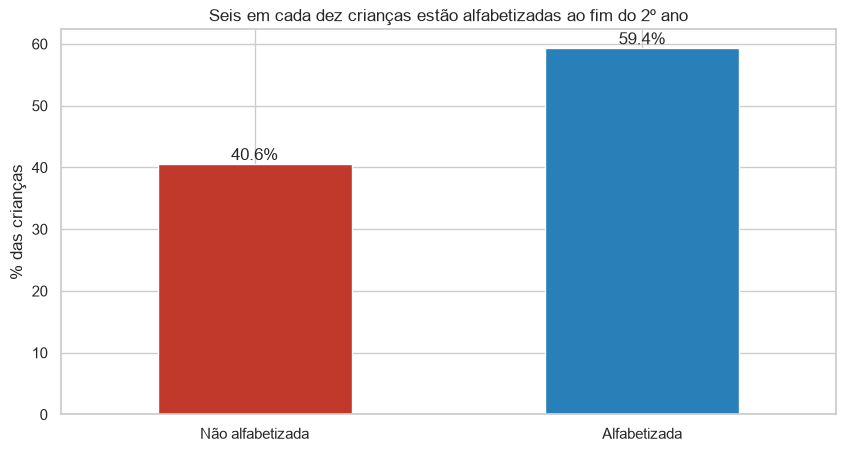

In [7]:
taxa_por_crianca = df["alfabetizado"].mean() * 100

ax = (df["alfabetizado"].value_counts(normalize=True).sort_index().mul(100)
      .plot(kind="bar", color=[COR_RS, "#2980b9"]))
ax.set_xticklabels(["Não alfabetizada", "Alfabetizada"], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("% das crianças")
ax.set_title("Seis em cada dez crianças estão alfabetizadas ao fim do 2º ano")
for barra in ax.patches:
    ax.annotate(f"{barra.get_height():.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom")
plt.show()

**59,4% das crianças estão alfabetizadas; 40,6% não estão.** Pensando no número frio de 1.6MM, são cerca de
650 mil crianças que chegam ao 3º ano sem ler e escrever com autonomia.

Para a modelagem, mantemos o equilíbrio : a classe menor tem 40% dos casos. Não tem motivos para
técnicas de reamostragem como o SMOTE. O que importa é o custo do erro: deixar de sinalizar uma
criança em risco é pior do que sinalizar uma que não precisava. Por isso o projeto escolhe o limiar
pelo *recall* (notebooks 02 e 03), em vez de olhar só a acurácia.

### 3.1 Contando por criança ou por município?

A taxa acima conta cada criança uma vez. Se contarmos cada **município** uma vez, a média muda:

In [8]:
# Uma linha por município: a taxa de 2024 vem dos próprios alunos, e o contexto é o mesmo em todos eles
mun = df.groupby("id_municipio").agg(
    taxa_2024=("alfabetizado", "mean"),
    alunos=("alfabetizado", "size"),
    sigla_uf=("sigla_uf", "first"),
    regiao=("regiao", "first"),
    **{c: (c, "first") for c in df.columns if c.startswith("mun_")},
)
mun["taxa_2024"] *= 100

print(f"Contando cada criança uma vez:   {taxa_por_crianca:.1f}%")
print(f"Contando cada município uma vez: {mun['taxa_2024'].mean():.1f}%")

Contando cada criança uma vez:   59.4%
Contando cada município uma vez: 62.9%


In [9]:
mun.head()

,taxa_2024,alunos,sigla_uf,regiao,mun_taxa_ano_anterior,mun_total_escolas,mun_alunos_por_docente,mun_alunos_por_turma,mun_pct_integral,mun_indice_infraestrutura,mun_pct_rural,mun_pct_transporte,mun_meta_ano_alvo,mun_distancia_meta_anterior,mun_elegivel_meta,mun_populacao,mun_densidade,mun_moradores_por_domicilio,mun_taxa_alfabetizacao_adulta,mun_idade_mediana,mun_indice_envelhecimento,mun_pct_indigena,mun_pct_quilombola,mun_pib_per_capita,mun_pct_va_agropecuaria,mun_pct_va_industria,mun_pct_va_servicos,mun_pct_va_administracao_publica
id_municipio,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1100015,68.000000,275,RO,Norte,64.55,12,26.218182,26.703704,0.000000,61.766066,92.094313,76.768377,67.08,-2.53,True,21440,3.033819,2.786225,0.91587,34.0,44.61,3.493470,0.536381,48803.311567,45.478492,4.065729,25.177734,25.278045
1100023,65.853659,1066,RO,Norte,62.30,20,24.004098,25.137339,14.307666,88.207842,33.532525,25.849411,65.22,-2.92,True,96152,21.719449,2.765532,0.94084,32.0,34.61,0.101922,0.000000,45592.551377,10.498219,14.606986,46.864787,28.030007
1100031,76.000000,75,RO,Norte,69.10,3,13.814815,14.346154,0.000000,79.714030,56.032172,54.155496,70.85,-1.75,True,5351,4.072298,2.720386,0.89824,38.0,64.14,0.186881,0.112129,56219.772005,60.143649,3.572293,15.784633,20.499426
1100049,66.080402,796,RO,Norte,62.51,18,18.773684,20.859649,7.232969,75.525652,63.694982,65.096720,65.39,-2.88,True,86494,22.803586,2.709966,0.93716,33.0,43.50,1.951580,0.000000,44494.045830,14.174923,9.834423,49.863552,26.127102
1100056,66.803279,244,RO,Norte,58.53,4,20.666667,22.425532,7.779886,76.723593,19.829222,17.457306,62.09,-3.56,True,15798,5.676608,2.689937,0.92152,34.0,47.01,0.145588,0.234207,63703.570072,24.820177,4.488707,50.505599,20.185517


**Por criança, 59,4%; por município, 62,9%.** A diferença de 3,5 pontos é a primeira pista de um
padrão que volta várias vezes nesta análise: se a média cai quando cada criança pesa igual, é porque
**os municípios com mais crianças alfabetizam menos**. É a hipótese H3, testada na seção 8.

> **Atenção:** a `taxa_2024` calculada aqui vem do próprio alvo. Na EDA isso é coerente, porque é
> só descrição. Ela **nunca** entra no modelo como variável: seria dar ao modelo a resposta da
> prova (ver o tratamento de vazamento no README, seção 3).

## 4. Onde está a diferença: entre os municípios ou dentro deles? (H0)

Esta é a seção mais importante do notebook.

Todas as variáveis da base descrevem o **município**. Duas crianças da mesma cidade recebem
exatamente o mesmo retrato, mesmo que uma tenha aprendido a ler e a outra não. Então vale medir:
quanto da diferença entre crianças alfabetizadas e não alfabetizadas é *diferença entre cidades*,
e quanto acontece *dentro da mesma cidade*?

Primeiro, quantas crianças cada município tem:

In [10]:
mun["alunos"].describe().round(0)

count     5450.0
mean       296.0
std       1102.0
min          6.0
25%         50.0
50%        103.0
75%        231.0
max      43340.0
Name: alunos, dtype: float64

A distribuição é muito desigual: metade dos municípios tem até 103 crianças avaliadas, mas o Rio
de Janeiro tem 43 mil e São Paulo, 42 mil. Isso tem duas consequências/impactos:

- **Pseudo-replicação.** Para as variáveis municipais, o tamanho real da amostra é o número de
  municípios (5.450), não o de crianças (1,6 milhão). Se treino e teste tiverem crianças da mesma
  cidade, o modelo "reconhece" o contexto e parece melhor do que é. Por isso a validação agrupa por
  `id_municipio` (`GroupKFold`).
- **Peso das grandes cidades.** Contando por criança, poucas capitais pesam mais do que milhares de
  municípios pequenos.

Agora, como as taxas variam de um município para outro:

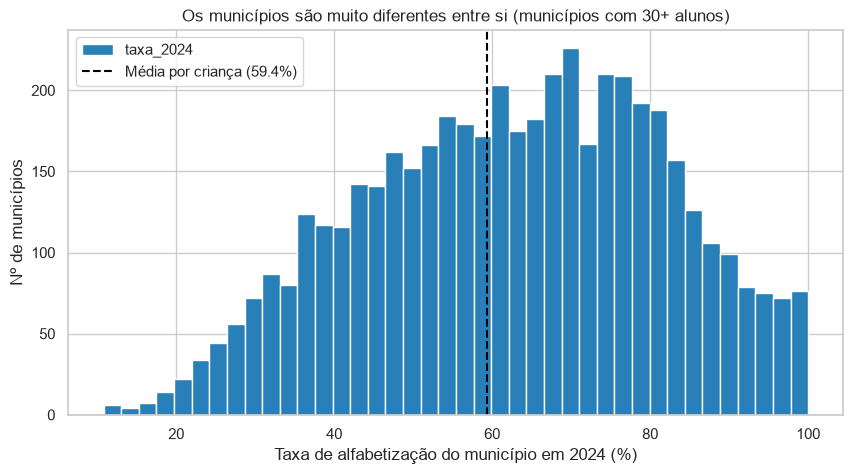

10% dos municípios alfabetizam menos de 36.5%; outros 10% alfabetizam mais de 87.0%.


In [11]:
mun_validos = mun[mun["alunos"] >= MIN_ALUNOS]

ax = mun_validos["taxa_2024"].plot(kind="hist", bins=40, color="#2980b9", edgecolor="white")
ax.axvline(taxa_por_crianca, color="black", linestyle="--", label=f"Média por criança ({taxa_por_crianca:.1f}%)")
ax.set_xlabel("Taxa de alfabetização do município em 2024 (%)")
ax.set_ylabel("Nº de municípios")
ax.set_title(f"Os municípios são muito diferentes entre si (municípios com {MIN_ALUNOS}+ alunos)")
ax.legend()
plt.show()

p10, p90 = mun_validos["taxa_2024"].quantile([0.1, 0.9])
print(f"10% dos municípios alfabetizam menos de {p10:.1f}%; outros 10% alfabetizam mais de {p90:.1f}%.")

Entre um município e outro, a distância é enorme: de cerca de 37% a 87%, considerando só os 10% de
cada ponta. Olhando esse gráfico, a impressão é de que o lugar onde a criança mora decide quase
tudo.

**Mas a decomposição da variação conta outra história.** O alvo é sim/não, e a variação total dele
é `p × (1 − p)`. A parte que é *entre municípios* é quanto a taxa de cada município se afasta da
média geral. O que sobra está *dentro* dos municípios.

In [12]:
taxas = mun_validos["taxa_2024"].sort_values().reset_index(drop=True)
print(f"Total: {len(taxas)}")
print(f"Posição 10%: {taxas[int(len(taxas) * 0.1)]:.1f}%")
print(f"Posição 90%: {taxas[int(len(taxas) * 0.9)]:.1f}%")
print(f"Abaixo de 36,5%: {(taxas < 36.5).mean() * 100:.1f}% dos municípios")

Total: 4833
Posição 10%: 36.5%
Posição 90%: 87.0%
Abaixo de 36,5%: 10.0% dos municípios


In [13]:
p = df["alfabetizado"].mean()
variacao_total = p * (1 - p)
variacao_entre = np.average((mun["taxa_2024"] / 100 - p) ** 2, weights=mun["alunos"])

parte_entre = variacao_entre / variacao_total * 100
print(f"Entre municípios: {parte_entre:.1f}%")
print(f"Dentro dos municípios: {100 - parte_entre:.1f}%")

Entre municípios: 10.6%
Dentro dos municípios: 89.4%


**Só 10,6% da variação está entre os municípios. Os outros 89,4% estão dentro deles.**

Os municípios são muito diferentes entre si, e ainda assim isso explica só uma pequena parte da
história. A maior parte da diferença está entre crianças da mesma cidade, dependendo da mesma sala.
Ela depende da família, da professora, da escola específica, do dia da prova. Não temos essas informações.

Esse número antecipa o resultado do projeto inteiro:

- **Nenhum modelo vai separar bem as crianças.** Ele só consegue trabalhar com os 10,6% que estão
  entre municípios. O ROC-AUC final fica perto de 0,67, e o README (seção 7) mostra que o teto
  teórico com estes dados é 0,70. O modelo não é fraco: os dados têm um limite já que devido a LGPD não temos informações na granularidade de aluno.
- **Os algoritmos vão empatar.** Se o limite está nos dados, trocar o algoritmo muda pouco (README,
  seção 6).
- **O uso legítimo é priorizar territórios, não rotular crianças.** O modelo estima o risco de "uma
  criança naquele contexto", não o de uma criança específica (README, seções 2 e 11).

> O README mede 11,6% / 88,4% no conjunto de teste, sem o RS. Aqui a conta usa a base inteira, por
> isso a pequena diferença. A conclusão acaba sendo a mesma.

## 5. O passado explica o presente? (H1)

Se a diferença entre municípios é a parte que dá para prever, o candidato mais óbvio é o próprio
resultado do município no ano anterior. Um ponto por município: a taxa de 2023 no eixo horizontal e
a de 2024 no vertical.

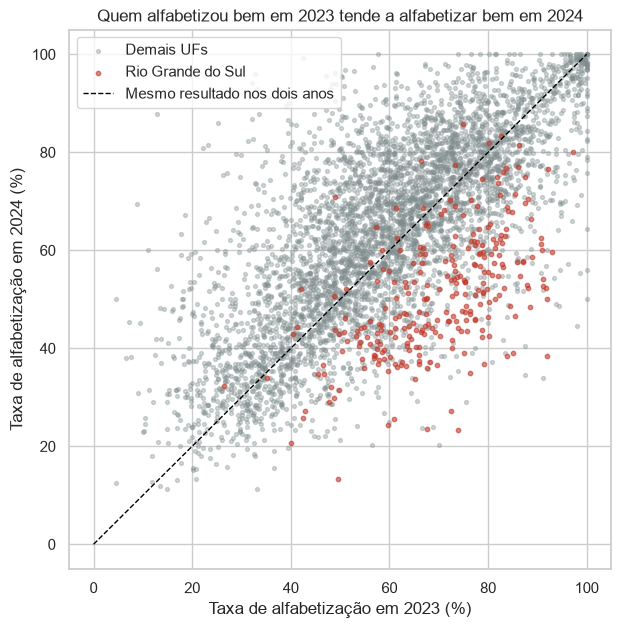

Correlação 2023 x 2024 (4803 municípios): 0.70
Sem o RS: 0.74


In [14]:
pares = mun_validos.dropna(subset=["mun_taxa_ano_anterior"])
eh_rs = pares["sigla_uf"] == "RS"

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pares.loc[~eh_rs, "mun_taxa_ano_anterior"], pares.loc[~eh_rs, "taxa_2024"],
           s=8, alpha=0.35, color=COR_DEMAIS, label="Demais UFs")
ax.scatter(pares.loc[eh_rs, "mun_taxa_ano_anterior"], pares.loc[eh_rs, "taxa_2024"],
           s=10, alpha=0.6, color=COR_RS, label="Rio Grande do Sul")
ax.plot([0, 100], [0, 100], color="black", linestyle="--", linewidth=1, label="Mesmo resultado nos dois anos")
ax.set_xlabel("Taxa de alfabetização em 2023 (%)")
ax.set_ylabel("Taxa de alfabetização em 2024 (%)")
ax.set_title("Quem alfabetizou bem em 2023 tende a alfabetizar bem em 2024")
ax.legend(loc="upper left")
plt.show()

print(f"Correlação 2023 x 2024 ({len(pares)} municípios): {pares['taxa_2024'].corr(pares['mun_taxa_ano_anterior']):.2f}")
sem_rs = pares[~eh_rs]
print(f"Sem o RS: {sem_rs['taxa_2024'].corr(sem_rs['mun_taxa_ano_anterior']):.2f}")

**A correlação entre os dois anos é de 0,70, e sobe para 0,74 sem o RS.** Para uma medida feita com
crianças diferentes em cada ano (quem estava no 2º ano em 2023 já passou para o 3º), é uma
persistência forte: o município carrega o resultado de um ano para o outro.

Duas leituras para guardar:

- **H1 se confirma.** O ano anterior vai dominar o modelo, e é o que o SHAP mostra depois (README,
  seção 8).
- **Mas persistência não é alavanca de política.** Dizer a um gestor que "o município vai mal porque
  ia mal" não ajuda ninguém. Por isso o projeto treina o modelo também **sem o histórico**, para ver
  o que o contexto explica sozinho. Essa decisão nasce aqui.

Os pontos vermelhos já mostram outra coisa: o Rio Grande do Sul está quase todo abaixo da diagonal.

## 6. O Rio Grande do Sul

Já havia sido notado algo estranho no RS desde a fase 2, e na Gold já marcamos o estado em `uf_anomala`. Comparar o
nível do RS com o resto do país não basta: um estado pode ter taxa baixa por diversos motivos. O que
torna o RS anômalo é a **queda acentuada** de um ano para o outro.

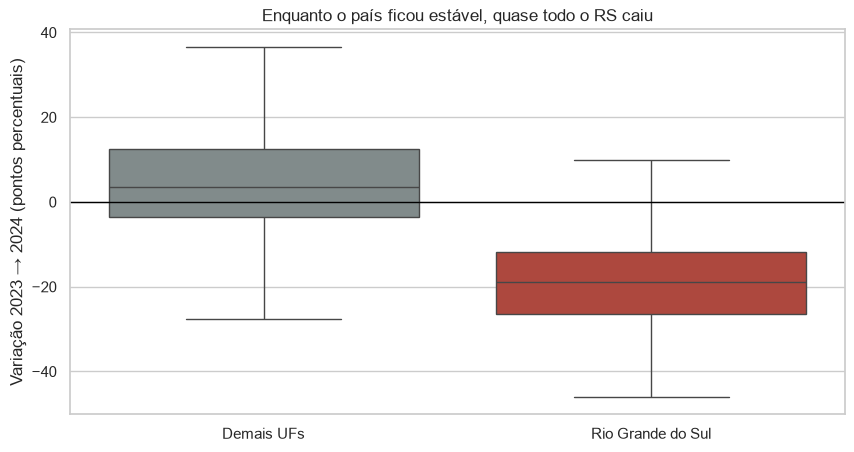

,municipios,variacao_mediana,pct_que_caiu
grupo,,,
Demais UFs,4532,3.6,37.2
Rio Grande do Sul,271,-18.9,93.4


In [15]:
pares = pares.assign(
    variacao=pares["taxa_2024"] - pares["mun_taxa_ano_anterior"],
    grupo=np.where(pares["sigla_uf"] == "RS", "Rio Grande do Sul", "Demais UFs"),
)

ax = sns.boxplot(data=pares, x="grupo", y="variacao", hue="grupo",
                 palette={"Rio Grande do Sul": COR_RS, "Demais UFs": COR_DEMAIS}, showfliers=False)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Variação 2023 → 2024 (pontos percentuais)")
ax.set_title("Enquanto o país ficou estável, quase todo o RS caiu")
plt.show()

resumo_rs = pares.groupby("grupo")["variacao"].agg(
    municipios="size",
    variacao_mediana="median",
    pct_que_caiu=lambda s: (s < 0).mean() * 100,
).round(1)
resumo_rs

**No RS, a taxa caiu 18,9 pontos no município típico, e 93,4% dos municípios pioraram.** No resto do
país, o município típico **subiu** 3,6 pontos, e só 37,2% pioraram. Não é um estado com desempenho
baixo: é um estado inteiro que mudou de patamar de um ano para o outro.

Há duas explicações possíveis, e os dados não separam uma da outra:

- **A medição mudou**, como a Fase 2 apontou;
- **As enchentes de 2024** fecharam escolas por semanas, no exato ano letivo avaliado.

Nas duas, é um choque de 2024, e não uma característica estável do estado.

**Decisão:** o RS **fica** na base. Se o efeito for real, excluí-lo tiraria justamente as crianças
de maior risco. A análise de sensibilidade do notebook 04 confirma que treinar com ou sem o estado
dá o mesmo resultado nos demais.

## 7. O território: a UF importa por si só? (H2)

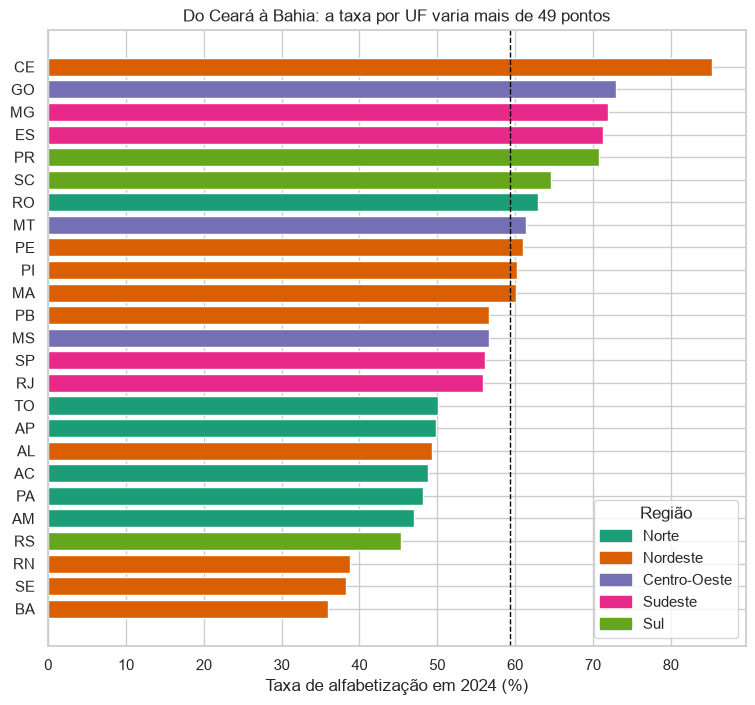

In [16]:
por_uf = df.groupby("sigla_uf").agg(taxa=("alfabetizado", "mean"), regiao=("regiao", "first"))
por_uf["taxa"] *= 100
por_uf = por_uf.sort_values("taxa")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(por_uf.index, por_uf["taxa"], color=por_uf["regiao"].map(CORES_REGIAO))
ax.axvline(taxa_por_crianca, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Taxa de alfabetização em 2024 (%)")
ax.set_title("Do Ceará à Bahia: a taxa por UF varia mais de 49 pontos")
legenda = [Patch(color=cor, label=regiao) for regiao, cor in CORES_REGIAO.items()]
ax.legend(handles=legenda, title="Região", loc="lower right")
plt.show()

O primeiro e o último lugar são **do mesmo Nordeste**: o Ceará alfabetiza 85,4% das crianças, a
Bahia, 36,0%. É uma distância maior do que entre quaisquer duas regiões.

A pergunta natural é se o Ceará simplesmente tem condições melhores. A tabela abaixo compara o
município típico (mediana) de cada estado:

In [17]:
colunas_contexto = {
    "taxa_2024": "Taxa de alfabetização 2024 (%)",
    "mun_pib_per_capita": "PIB per capita (R$)",
    "mun_taxa_alfabetizacao_adulta": "Alfabetização adulta (0 a 1)",
    "mun_moradores_por_domicilio": "Moradores por domicílio",
    "mun_indice_infraestrutura": "Índice de infraestrutura escolar",
    "mun_pct_integral": "Matrículas em tempo integral (%)",
}
ce_ba = (mun[mun["sigla_uf"].isin(["CE", "BA"])]
         .groupby("sigla_uf")[list(colunas_contexto)].median()
         .rename(columns=colunas_contexto).T.round(2))
ce_ba[["CE", "BA"]]

sigla_uf,CE,BA
Taxa de alfabetização 2024 (%),93.02,35.72
PIB per capita (R$),14760.66,15263.93
Alfabetização adulta (0 a 1),0.79,0.82
Moradores por domicílio,2.93,2.85
Índice de infraestrutura escolar,73.67,66.42
Matrículas em tempo integral (%),42.41,20.48


**Os dois estados têm contextos muito parecidos e resultados opostos.** No município típico, o
Ceará alfabetiza 93% das crianças e a Bahia 36%. Mesmo assim, o PIB per capita, a alfabetização
dos adultos e moradores por domicílio são quase iguais. O Ceará não é mais rico, e a Bahia tem até
volume maior de adultos alfabetizados. A infraestrutura é um pouco melhor no Ceará (74 contra 66), e
a seção 9 mostra que ela explica pouco. A diferença que salta aos olhos é o tempo integral: 42% das
matrículas no Ceará, contra 20% na Bahia.

Isso sugere que **H2 se confirma**: há algo no estado que as condições socioeconômicas não explicam.
O README (seção 8) chega à mesma conclusão pelo modelo: sem o histórico, a UF é o fator mais forte,
e o Ceará e a Bahia ficam nos extremos opostos.

O Ceará mantém desde 2007 um programa estadual de alfabetização em colaboração com os municípios, o
PAIC( https://imdsbrasil.org/impacto/programa-alfabetizacao-na-idade-certa-paic-no-ceara/ ). O efeito é coerente com ele. Mas a avaliação também é aplicada por sistemas estaduais, e
diferenças de medição apareceriam do mesmo jeito. A EDA mostra o contraste; não consegue dizer a
causa.

## 8. O tamanho do município (H3)

Na seção 3 vimos que a média cai quando cada criança pesa igual. Aqui olhamos isso diretamente,
separando os municípios por faixa de população.

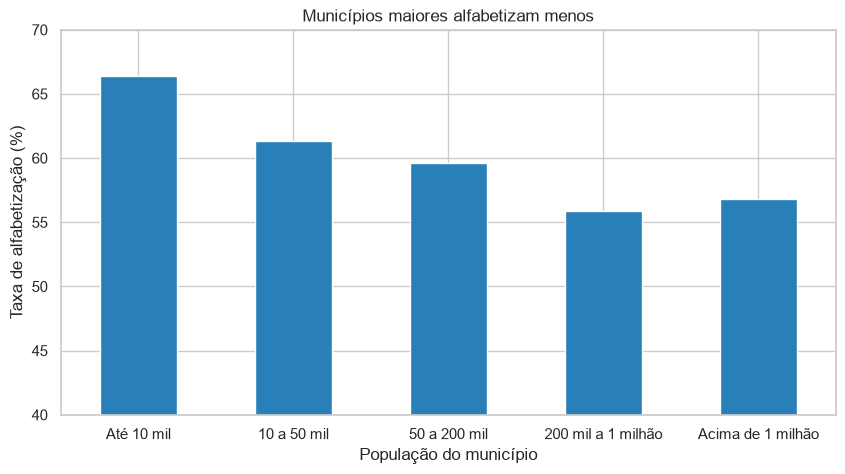

,taxa,pct_das_criancas
mun_populacao,,
Até 10 mil,66.4,7.8
10 a 50 mil,61.3,29.7
50 a 200 mil,59.6,25.3
200 mil a 1 milhão,55.9,24.6
Acima de 1 milhão,56.8,12.5


In [18]:
faixas_pop = pd.cut(
    df["mun_populacao"],
    [0, 10_000, 50_000, 200_000, 1_000_000, np.inf],
    labels=["Até 10 mil", "10 a 50 mil", "50 a 200 mil", "200 mil a 1 milhão", "Acima de 1 milhão"],
)
por_porte = df.groupby(faixas_pop, observed=True).agg(
    taxa=("alfabetizado", "mean"), alunos=("alfabetizado", "size"))
por_porte["taxa"] = (por_porte["taxa"] * 100).round(1)
por_porte["pct_das_criancas"] = (por_porte["alunos"] / por_porte["alunos"].sum() * 100).round(1)

ax = por_porte["taxa"].plot(kind="bar", color="#2980b9")
ax.set_xlabel("População do município")
ax.set_ylabel("Taxa de alfabetização (%)")
ax.set_ylim(40, 70)
ax.set_title("Municípios maiores alfabetizam menos")
ax.tick_params(axis="x", rotation=0)
plt.show()

por_porte[["taxa", "pct_das_criancas"]]

**Os municípios com até 10 mil habitantes alfabetizam 66,4%; os de 200 mil a 1 milhão, 55,9%.** São
dez pontos de diferença, e quase dois terços das crianças estão nas faixas acima de 50 mil. As
metrópoles (acima de 1 milhão) se recuperam um pouco, mas continuam bem abaixo das cidades pequenas.

É um resultado contra a intuição. Cidades grandes costumam ter mais renda, mais escolas e mais
estrutura. Uma explicação possível é a escala: redes grandes são mais difíceis de acompanhar de
perto, e cada criança tem menos chance de ser notada. Outra é que as grandes cidades concentram
áreas de pobreza que a média municipal esconde. A EDA não separa as duas: os dados descrevem o
município como um todo, sem informação por bairro ou por escola. O id_escola é um código
sintético e não pode ser cruzado com o Censo Escolar (README, seção 10).

**H3 se confirma**, e reaparece depois de forma independente: no SHAP ("a escala pesa contra") e na
clusterização, em que o grupo urbano mais rico alfabetiza menos que o interior estruturado (README,
seções 8 e 9). A capital paulista, a cidade mais rica do grupo, alfabetiza 48,5%.

## 9. A infraestrutura escolar (H4)

A ideia de que escolas mais bem equipadas alfabetizam mais é intuitiva, e é o tipo de achado que
vira recomendação de política ("invista em infraestrutura"). Por isso vale olhar com cuidado.

### 9.1 Existe um gradiente?

Dividimos os municípios em quatro grupos do mesmo tamanho (quartis) pelo índice de infraestrutura
escolar e comparamos a taxa de alfabetização de cada grupo. A conta é feita de dois jeitos: com cada
município contando uma vez, e com cada criança contando uma vez.

In [19]:
rotulos_quartil = ["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]

# Grão do município: cada município conta uma vez
mun["quartil_infra"] = pd.qcut(mun["mun_indice_infraestrutura"], 4, labels=rotulos_quartil)
grao_municipio = mun.groupby("quartil_infra", observed=True).agg(
    indice_medio=("mun_indice_infraestrutura", "mean"),
    taxa_media=("taxa_2024", "mean"),
    alunos_por_docente=("mun_alunos_por_docente", "mean"),
)

# Grão da criança: cada criança conta uma vez
quartil_aluno = pd.qcut(df["mun_indice_infraestrutura"], 4, labels=rotulos_quartil)
grao_crianca = df.groupby(quartil_aluno, observed=True)["alfabetizado"].mean().mul(100)

comparacao = grao_municipio.assign(taxa_por_crianca=grao_crianca).round(1)
comparacao.index.name = "quartil_infra"
comparacao

,indice_medio,taxa_media,alunos_por_docente,taxa_por_crianca
quartil_infra,,,,
Q1 (menor),58.5,57.7,17.9,55.4
Q2,73.4,60.7,17.6,58.3
Q3,83.4,66.1,15.8,61.5
Q4 (maior),96.3,67.1,14.9,62.3


In [20]:
gap_municipio = comparacao["taxa_media"].iloc[-1] - comparacao["taxa_media"].iloc[0]
gap_crianca = comparacao["taxa_por_crianca"].iloc[-1] - comparacao["taxa_por_crianca"].iloc[0]
print(f"Diferença Q4 - Q1, cada município conta uma vez: {gap_municipio:.1f} pontos")
print(f"Diferença Q4 - Q1, cada criança conta uma vez:   {gap_crianca:.1f} pontos")

Diferença Q4 - Q1, cada município conta uma vez: 9.4 pontos
Diferença Q4 - Q1, cada criança conta uma vez:   6.9 pontos


**Existe um gradiente:** a taxa sobe de 57,7% nos municípios com a pior infraestrutura (Q1) para
67,1% nos de melhor (Q4), quase 10 pontos. Os alunos por docente também caem ao longo dos quartis
(de 17,9 para 14,9): onde as escolas são mais equipadas, há também mais professores por aluno.

Contando por criança, o gradiente encolhe de 9,4 para 6,9 pontos. Faz sentido com a seção 8: as
grandes cidades têm boa infraestrutura e taxas mais baixas, e pesam mais quando cada criança conta.

### 9.2 E dentro de cada região?

Escolas bem equipadas estão onde há mais renda, e a renda varia muito por região. Se compararmos só
municípios da mesma região, o gradiente continua?

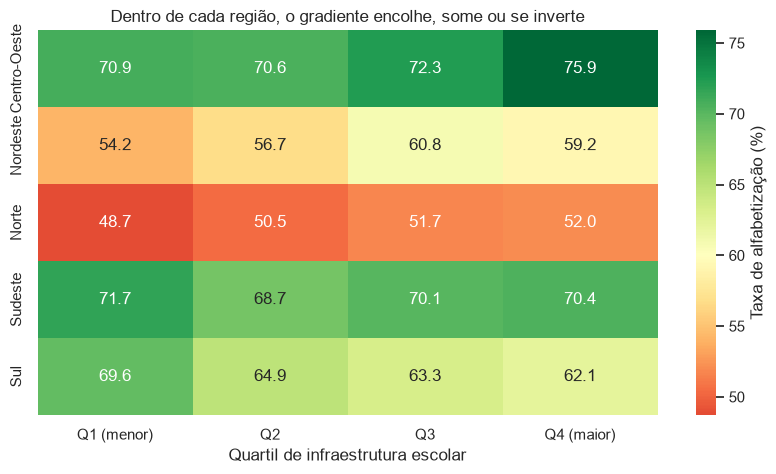

PIB per capita mediano por quartil de infraestrutura (R$):
quartil_infra
Q1 (menor)    18000.0
Q2            23000.0
Q3            37000.0
Q4 (maior)    44000.0


In [21]:
dentro_regiao = (mun.groupby(["regiao", "quartil_infra"], observed=True)["taxa_2024"]
                 .mean().unstack().round(1))

ax = sns.heatmap(dentro_regiao, annot=True, fmt=".1f", cmap="RdYlGn", center=60,
                 cbar_kws={"label": "Taxa de alfabetização (%)"})
ax.set_xlabel("Quartil de infraestrutura escolar")
ax.set_ylabel("")
ax.set_title("Dentro de cada região, o gradiente encolhe, some ou se inverte")
plt.show()

pib_por_quartil = mun.groupby("quartil_infra", observed=True)["mun_pib_per_capita"].median().round(-3)
print("PIB per capita mediano por quartil de infraestrutura (R$):")
print(pib_por_quartil.to_string())

**Aqui o gradiente muda de figura.** Dentro de cada região:

- no **Norte**, no **Nordeste** e no **Centro-Oeste**, o gradiente existe, mas é menor (3 a 5
  pontos entre o Q1 e o Q4);
- no **Sudeste**, praticamente some, quase linear;
- no **Sul**, **se inverte**: os municípios com melhor infraestrutura alfabetizam *menos*.

E o PIB per capita mediano sobe de cerca de R$ 18 mil no Q1 para R$ 44 mil no Q4. A
infraestrutura anda junto com a riqueza e com a região. Boa parte do gradiente nacional é isso:
regiões mais ricas, com escolas mais equipadas, e não escolas mais equipadas alfabetizando mais.

É o exemplo clássico de **variável de confusão**: uma associação real que não é causa. **H4 se confirma só pela metade.** O README (seção 8) chega ao mesmo ponto pelo
modelo: quando o contexto do município já é conhecido, a infraestrutura pesa muito pouco.

## 10. A condição das famílias e da economia (H5)

### 10.1 Uma correlação que depende de como se olha

O jeito mais rápido de procurar relações é a correlação de cada variável com o alvo. Mas o grão
importa muito. Abaixo, a mesma correlação calculada de duas formas:

- **por criança:** 1,6 milhão de pontos, cada um com o alvo 0 ou 1;
- **por município:** um ponto por cidade, com a taxa de alfabetização (Spearman, que não se deixa
  levar por valores extremos).

In [22]:
variaveis = {
    "mun_taxa_ano_anterior": "Taxa do ano anterior",
    "mun_distancia_meta_anterior": "Distância da meta em 2023",
    "mun_indice_envelhecimento": "Índice de envelhecimento",
    "mun_moradores_por_domicilio": "Moradores por domicílio",
    "mun_indice_infraestrutura": "Infraestrutura escolar",
    "mun_pib_per_capita": "PIB per capita",
    "mun_populacao": "População",
    "mun_taxa_alfabetizacao_adulta": "Alfabetização adulta",
    "mun_pct_integral": "Tempo integral",
}
alvo_numerico = df["alfabetizado"].astype(float)

correlacoes = pd.DataFrame({
    "por_crianca": {nome: alvo_numerico.corr(df[col]) for col, nome in variaveis.items()},
    "por_municipio": {nome: mun["taxa_2024"].corr(mun[col], method="spearman") for col, nome in variaveis.items()},
}).round(3)
correlacoes.sort_values("por_municipio", key=abs, ascending=False)

,por_crianca,por_municipio
Taxa do ano anterior,0.257,0.627
Distância da meta em 2023,0.221,0.625
Índice de envelhecimento,0.053,0.246
Moradores por domicílio,-0.050,-0.230
Infraestrutura escolar,0.055,0.212
População,-0.031,-0.188
Alfabetização adulta,-0.001,0.121
PIB per capita,0.010,0.117
Tempo integral,0.057,-0.059


**Olhando por criança, parece que nada se relaciona muito com a alfabetização:** a maior correlação
é 0,26. **Olhando por município, as relações aparecem com força:** a taxa do ano anterior chega a
0,63, e envelhecimento, adensamento e infraestrutura ficam entre 0,2 e 0,25.

Não há contradição. É a seção 4 de novo, vista por outro ângulo: as variáveis municipais explicam
bem **por que um município difere do outro**, e não explicam **por que duas crianças da mesma cidade
diferem**. Como 89% da variação está dentro das cidades, a correlação por criança fica pequena por
construção.

> Por isso este notebook não traz o mapa de calor com todas as variáveis no grão da criança: ele
> levaria à conclusão errada de que nada importa. As correlações *entre* as variáveis (redundância)
> estão no notebook 02.

### 10.2 Como a taxa muda ao longo de cada variável

Dividimos os municípios em cinco grupos iguais (quintis) de cada variável e olhamos a taxa média em
cada grupo.

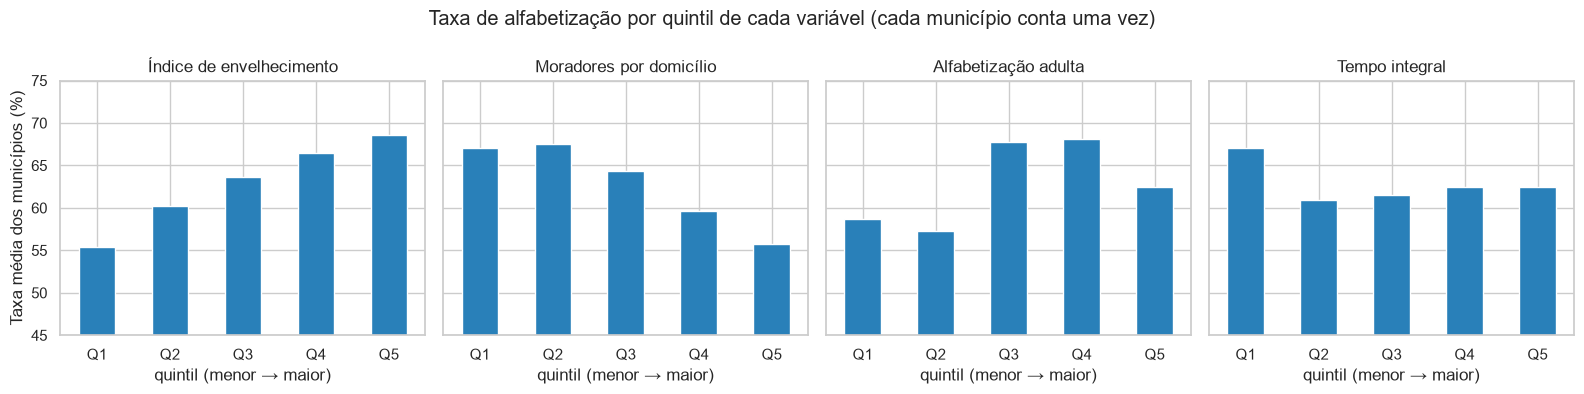

In [23]:
variaveis_faixas = {
    "mun_indice_envelhecimento": "Índice de envelhecimento",
    "mun_moradores_por_domicilio": "Moradores por domicílio",
    "mun_taxa_alfabetizacao_adulta": "Alfabetização adulta",
    "mun_pct_integral": "Tempo integral",
}
fig, eixos = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (col, nome) in zip(eixos, variaveis_faixas.items()):
    # rank evita empates na borda dos quintis (o tempo integral tem muitos zeros)
    quintil = pd.qcut(mun[col].rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    mun.groupby(quintil, observed=True)["taxa_2024"].mean().plot(kind="bar", ax=ax, color="#2980b9")
    ax.set_title(nome)
    ax.set_xlabel("quintil (menor → maior)")
    ax.tick_params(axis="x", rotation=0)
eixos[0].set_ylabel("Taxa média dos municípios (%)")
eixos[0].set_ylim(45, 75)
fig.suptitle("Taxa de alfabetização por quintil de cada variável (cada município conta uma vez)")
plt.tight_layout()
plt.show()

Cada painel conta uma parte da história:

- **Envelhecimento:** a taxa sobe de forma contínua, de 55% para 69%. Não é que pessoas mais velhas
  alfabetizem crianças: municípios mais envelhecidos estão mais adiante na transição demográfica,
  típica das regiões mais desenvolvidas. O índice funciona como um resumo do desenvolvimento.
- **Moradores por domicílio:** quanto mais gente por casa, menor a taxa (de 67% para 56%). Casas
  mais cheias costumam indicar famílias mais pobres e menos espaço e tempo para a criança estudar.
- **Alfabetização adulta:** fica baixa nos dois primeiros quintis, salta no 3º e no 4º, e **cai no
  5º**. Duas coisas vêm junto com os adultos mais escolarizados: cidades maiores (a população
  mediana do 5º quintil é mais que o dobro da dos outros) e o RS, que é um quarto desse grupo. A
  escala (seção 8) e a queda gaúcha (seção 6) puxam a taxa para baixo. E o 1º quintil é quase todo
  do Nordeste. Uma variável sozinha raramente conta a história inteira.
- **Tempo integral:** o 1º quintil (quase sem tempo integral) tem a maior taxa, e o resto fica
  parecido. À primeira vista, o tempo integral não ajudaria. Vale olhar com calma.

### 10.3 O caso do tempo integral

In [24]:
integral = pd.DataFrame({
    "tempo_integral_mediano_%": mun.groupby("regiao")["mun_pct_integral"].median(),
    "correlacao_com_taxa": mun.groupby("regiao")[["taxa_2024", "mun_pct_integral"]].apply(
        lambda g: g["taxa_2024"].corr(g["mun_pct_integral"], method="spearman")),
}).round(2)
print(f"Correlação no país inteiro: {mun['taxa_2024'].corr(mun['mun_pct_integral'], method='spearman'):.2f}")
integral

Correlação no país inteiro: -0.06


,tempo_integral_mediano_%,correlacao_com_taxa
regiao,,
Centro-Oeste,3.72,-0.01
Nordeste,21.31,0.15
Norte,9.99,-0.08
Sudeste,7.53,-0.01
Sul,6.79,-0.03


**No país inteiro, a correlação do tempo integral com a taxa é levemente negativa (−0,06). No
Nordeste, é positiva (0,15).**

O motivo é a região. O Nordeste tem de longe mais tempo integral (21% das matrículas no município
típico, contra 4% a 10% nas outras regiões) e também taxas mais baixas na média. Misturando tudo,
a região "esconde" o efeito. Olhando dentro do Nordeste, onde o tempo integral de fato varia,
mais tempo integral anda junto com mais alfabetização.

Nas outras regiões, ele quase não existe, e a correlação fica perto de zero. Não dá para concluir
nada ali.

Fica a hipótese: **o efeito do tempo integral só aparece quando a região é levada em conta.** O
modelo confirma depois: no SHAP, o tempo integral é a única variável escolar com peso relevante, e
está associado a menos risco (README, seção 8). E é também a única diferença clara entre Ceará e
Bahia na seção 7.

**H5 se confirma**: famílias em casas mais cheias e municípios menos desenvolvidos alfabetizam menos.
Mas as relações são mais fracas do que as do histórico e da UF, e várias se misturam com região e
tamanho.

## 11. As metas: quem fica para trás? (H6)

Cada município pactuou uma meta de alfabetização para 2024. Uma das perguntas do enunciado é como
prever quais vão falhar. Antes de qualquer modelo, quantos ficaram abaixo?

Usamos os municípios com meta publicada e pelo menos 30 alunos. "Abaixo em 2023" significa que, no
fim de 2023, a taxa ainda estava abaixo da meta de 2024 (`mun_distancia_meta_anterior` negativa).

In [25]:
com_meta = mun[(mun["mun_elegivel_meta"] == True) & (mun["alunos"] >= MIN_ALUNOS)].dropna(
    subset=["mun_meta_ano_alvo", "mun_distancia_meta_anterior"])

abaixo_2024 = (com_meta["taxa_2024"] < com_meta["mun_meta_ano_alvo"]).rename("abaixo da meta em 2024")
abaixo_2023 = (com_meta["mun_distancia_meta_anterior"] < 0).map(
    {True: "Já abaixo em 2023", False: "Acima em 2023"}).rename("situação em 2023")

print(f"Municípios analisados: {len(com_meta):,}".replace(",", "."))
print(f"Ficaram abaixo da meta em 2024: {abaixo_2024.mean() * 100:.1f}%")
pd.crosstab(abaixo_2023, abaixo_2024, normalize="index").mul(100).round(1)

Municípios analisados: 4.677
Ficaram abaixo da meta em 2024: 45.9%


abaixo da meta em 2024,False,True
situação em 2023,,
Acima em 2023,59.8,40.2
Já abaixo em 2023,52.9,47.1


**Quase metade dos municípios (45,9%) ficou abaixo da meta de 2024.** Não são casos isolados.

O mais interessante é a tabela: entre os que já estavam abaixo em 2023, 47,1% continuaram abaixo;
entre os que estavam acima, 40,2% caíram para baixo. Estar atrás antes aumenta o risco, mas só um
pouco. Uma regra simples como "quem está abaixo hoje vai continuar abaixo" erraria muito.

Isso justifica o modelo: para antecipar quem vai falhar, é preciso combinar o histórico com o
contexto. **H6 se confirma, mas é um sinal fraco sozinho.** O README (seção 11) faz o backtest dessa
previsão para 2024.

## 12. Que regiões se parecem?

Uma das perguntas do enunciado é quais regiões têm padrões semelhantes. Antes da clusterização
(README, seção 9), um retrato simples: o município típico de cada região.

In [26]:
perfil = mun.groupby("regiao").agg(
    municipios=("taxa_2024", "size"),
    taxa_2024=("taxa_2024", "median"),
    pib_per_capita=("mun_pib_per_capita", "median"),
    alfabetizacao_adulta=("mun_taxa_alfabetizacao_adulta", "median"),
    moradores_por_domicilio=("mun_moradores_por_domicilio", "median"),
    infraestrutura=("mun_indice_infraestrutura", "median"),
    tempo_integral=("mun_pct_integral", "median"),
    populacao=("mun_populacao", "median"),
).round(2)
perfil.T

regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
municipios,464.00,1781.00,435.00,1626.00,1144.00
taxa_2024,73.47,52.63,49.68,70.74,66.56
pib_per_capita,49747.61,15200.18,25703.58,33357.36,48628.80
alfabetizacao_adulta,0.91,0.79,0.88,0.94,0.95
moradores_por_domicilio,2.72,2.94,3.13,2.71,2.66
infraestrutura,80.48,69.37,63.05,85.56,83.33
tempo_integral,3.72,21.31,9.99,7.53,6.79
populacao,8918.00,13778.00,15707.00,11006.50,7525.00


Três perfis aparecem:

- **Sul, Sudeste e Centro-Oeste** se parecem: PIB per capita mais alto (R$ 33 mil a R$ 50 mil),
  adultos alfabetizados (91% a 95%), boa infraestrutura e pouco tempo integral. São também as
  regiões com as maiores taxas (67% a 73% no município típico).
- **O Nordeste** tem o contexto econômico mais difícil: PIB per capita de R$ 15 mil e 79% de adultos
  alfabetizados. Mesmo assim, alfabetiza mais que o Norte (53% contra 50%). E é, de longe, a região
  com mais tempo integral.
- **O Norte** é o caso que mais chama atenção. Tem mais renda (R$ 26 mil) e adultos mais
  alfabetizados (88%) que o Nordeste, mas as casas mais cheias (3,1 moradores), a pior
  infraestrutura escolar e as menores taxas. Renda, sozinha, não explica o resultado.

A clusterização do README confirma esse desenho com mais detalhe: o Nordeste fica quase todo num
grupo só, e Sul, Sudeste e Centro-Oeste se espalham pelos mesmos grupos.

## 13. Pontos de atenção de leitura com os dados

Três pontos que podem enganar quem olhar os números brutos. O tratamento de cada um está no
notebook 02 (seção 7) e no README (seção 10); aqui fica só o aviso.

In [27]:
acima_de_100 = {
    col: (mun[col] > 100).mean() * 100 for col in ["mun_pct_rural", "mun_pct_transporte"]
}
for col, pct in acima_de_100.items():
    print(f"{col}: {pct:.1f}% dos municípios passam de 100%")

maior_turma = mun["mun_alunos_por_turma"].idxmax()
print(f"\nAlunos por turma: mediana {mun['mun_alunos_por_turma'].median():.1f}, "
      f"máximo {mun.loc[maior_turma, 'mun_alunos_por_turma']:.1f} (município {maior_turma}, "
      f"{mun.loc[maior_turma, 'sigla_uf']})")

print(f"\nAlfabetização adulta vai de {mun['mun_taxa_alfabetizacao_adulta'].min():.2f} "
      f"a {mun['mun_taxa_alfabetizacao_adulta'].max():.2f} (escala de 0 a 1)")

mun_pct_rural: 23.5% dos municípios passam de 100%
mun_pct_transporte: 20.3% dos municípios passam de 100%

Alunos por turma: mediana 20.3, máximo 109.9 (município 1200328, AC)

Alfabetização adulta vai de 0.65 a 0.99 (escala de 0 a 1)


- **Percentuais acima de 100%.** `mun_pct_rural` e `mun_pct_transporte` passam de 100% em cerca de
  20% dos municípios. Não é erro de digitação: no Censo Escolar, o numerador conta as matrículas de
  todas as etapas, e o denominador, só as dos anos iniciais.
- **Um valor extremo.** Jordão (AC), código 1200328, tem 109,9 alunos por turma, contra 20,3 no
  município típico. O motivo é parecido: turmas multisseriadas em áreas indígenas não contam como
  turmas de anos iniciais, e o denominador fica pequeno demais.
- **Escalas diferentes.** A alfabetização adulta está de 0 a 1, enquanto as outras taxas vão de 0 a
  100. Não muda nada para o modelo (as variáveis são padronizadas), mas confunde na leitura.

Nos dois primeiros casos, o número descreve uma conta, não a realidade. O pré-processamento aplica
um teto no percentil 99, aprendido só no treino (README, seções 5 e 10).

## 14. Síntese: o que a exploração ensinou à modelagem

| Achado da EDA | O que isso significa | Confirmado em |
|---|---|---|
| Só 10,6% da variação está entre municípios; 89,4% está dentro deles | Há um teto baixo para qualquer modelo; validação agrupada por município é obrigatória; o modelo serve para priorizar territórios, não para rotular crianças | README, seções 7 e 11 |
| Taxa de 2023 e de 2024 com correlação de 0,70 (0,74 sem o RS) | O histórico vai dominar o modelo; vale analisar também sem ele, para ver o que o contexto explica | Notebook 05; README, seção 8 |
| Ceará (85,4%) e Bahia (36,0%) com contextos parecidos | A UF tem efeito próprio, que as condições socioeconômicas não explicam | README, seção 8 |
| Municípios grandes alfabetizam menos (66,4% até 10 mil hab., 55,9% de 200 mil a 1 milhão) | A escala pesa contra; contar por criança e por município dá resultados diferentes | README, seções 7, 8 e 9 |
| Municípios com melhor infraestrutura alfabetizam mais (57,7% → 67,1%), mas o gradiente some ou se inverte dentro das regiões | A infraestrutura acompanha a riqueza e a região; é associação, não causa | README, seção 8 |
| O tempo integral só se relaciona com a taxa onde ele existe (Nordeste) | O efeito aparece quando a região é considerada | README, seção 8 (SHAP) |
| No RS, queda mediana de 18,9 pontos e 93,4% dos municípios em queda | Choque de 2024; o RS fica no treino, com análise de sensibilidade | Notebook 04 |
| 45,9% dos municípios abaixo da meta; estar abaixo antes aumenta pouco o risco | Uma regra simples não basta; o histórico precisa ser combinado com o contexto | README, seção 11 |
| 59,4% das crianças alfabetizadas | Sem reamostragem; o recall é controlado pelo limiar | Notebooks 02 e 03 |
| Gold íntegra: sem vazamento, sem duplicatas, nulos pequenos e explicados | A base pode ser usada como está; os nulos são imputados no pipeline | Notebook 02, seção 8 |

**Em uma frase:** o lugar onde a criança mora diz muito sobre a chance de ela se alfabetizar, mas
diz pouco sobre *qual* criança vai se alfabetizar. É por isso que este projeto usa o modelo para
apontar territórios que precisam de atenção, e não para julgar crianças, pois tem dados na granularidade necessária.